In [2]:
# imports to enable the notebook to access the src folder
import sys
import os
import numpy as np
sys.path.append(os.path.dirname(os.getcwd()))

# import Antoine calculator
from src.pure import AntoineCalculator

# instantiate the calculator
antoine_calc = AntoineCalculator()

In [3]:
# define compound
#compound = {'CH3':3, 'CH':1, 'CH2COO':1}#{'H2O': 1}
#compound = {'H2O': 1}
#compound = {'DOH': 1}
compound = {'CH3':2, 'CH2COO':2}
# instantiate property calculator
from src.pure import PropertyCalculator
pure_calc = PropertyCalculator()

# calculate the required properties
critical_props = pure_calc.calculate(compound, properties=['tc', 'pc', 'tb', 'ac', 'hv'])

# solve for the Antoine parameters
results_ac = antoine_calc.calculate_antoine_parameters(compound, critical_properties=critical_props, method="acentric_factor")

# print the anointe parameters
print(f"A: {results_ac['A']}")
print(f"B: {results_ac['B']}")
print(f"C: {results_ac['C']}")
# print the range of T: tb to Tc
print(f"T range: {critical_props['tb']} K to {critical_props['tc']} K")

Characteristic points (T [K], P [bar]): (439.0035375529277, 1.01325), (303.79051752783437, 0.84048000439479), (433.986453611192, 31.003913926341408)
A: -0.07230188828684092
B: -0.4119802718619212
C: -433.7229916803135
T range: 439.0035375529277 K to 433.986453611192 K


In [15]:
# solve for the Antoine parameters
results_hv = antoine_calc.calculate_antoine_parameters(compound, critical_properties=critical_props, method="enthalpy_vap")

# print the anointe parameters
print(f"A: {results_hv['A']}")
print(f"B: {results_hv['B']}")
print(f"C: {results_hv['C']}")
# print the range of T: tb to Tc
print(f"T range: {critical_props['tb']} K to {critical_props['tc']} K")

Characteristic points (T [K], P [bar]): (298.15, 0.02506021999224081), (387.6976301304226, 1.01325), (462.8889622678359, 31.203983022183035)
A: -31.567237900203438
B: 52730.022106521195
C: -2057.798604857644
T range: 387.6976301304226 K to 462.8889622678359 K


In [16]:
# solve for the Antoine parameters
results_min = antoine_calc.calculate_antoine_parameters(compound, critical_properties=critical_props, method="minimal")

# print the anointe parameters
print(f"A: {results_min['A']}")
print(f"B: {results_min['B']}")
print(f"C: {results_min['C']}")
# print the range of T: tb to Tc
print(f"T range: {critical_props['tb']} K to {critical_props['tc']} K")

A: 9.169102273778762
B: 3552.622904882318
C: 0.0
T range: 387.6976301304226 K to 462.8889622678359 K


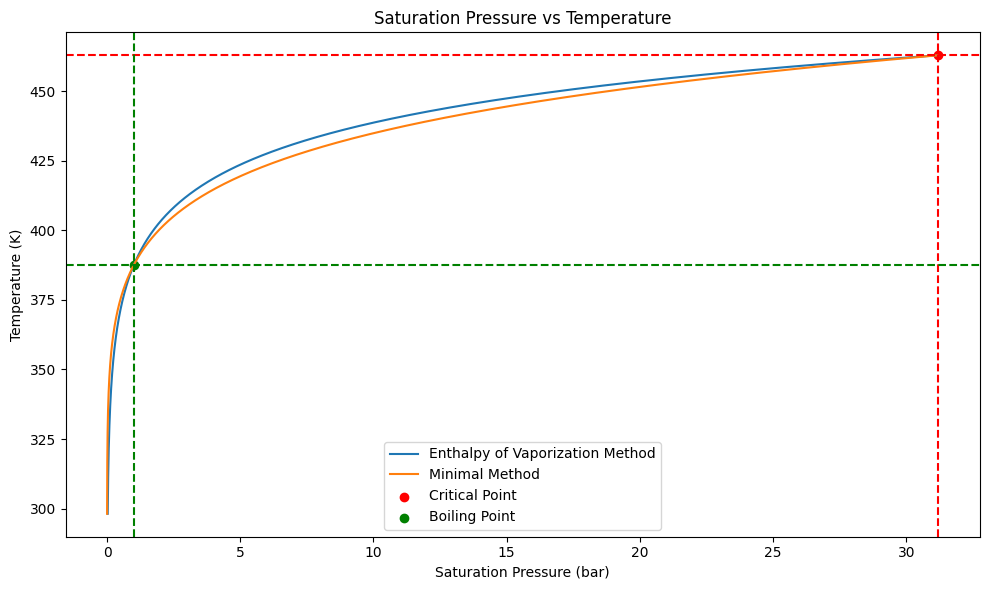

In [20]:
# create T range
T_range = np.linspace(298.15, critical_props['tc'], 1000)
# calculate Psat using the calculated Antoine parameters
P_ac = antoine_calc.antoine_correlation(A=results_ac['A'],
                                        B=results_ac['B'],
                                        C=results_ac['C'],
                                        T=T_range)
P_hv = antoine_calc.antoine_correlation(A=results_hv['A'],
                                        B=results_hv['B'],
                                        C=results_hv['C'],
                                        T=T_range)
P_min = antoine_calc.antoine_correlation(A=results_min['A'],
                                         B=results_min['B'],
                                         C=results_min['C'],
                                         T=T_range)
# plot the results
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
#plt.plot(P_ac,T_range,  label='Acentric Factor Method')
plt.plot(P_hv,T_range, label='Enthalpy of Vaporization Method')
plt.plot(P_min,T_range, label='Minimal Method')

plt.xlabel('Saturation Pressure (bar)')
plt.ylabel('Temperature (K)')
plt.title('Saturation Pressure vs Temperature')
# highlight the critical point
plt.scatter(critical_props['pc'], critical_props['tc'], color='red', label='Critical Point')
plt.axvline(x=critical_props['pc'], color='red', linestyle='--')
plt.axhline(y=critical_props['tc'], color='red', linestyle='--')
# highlight the boiling point
plt.scatter(1.01325, critical_props['tb'], color='green', label='Boiling Point')
plt.axvline(x=1.01325, color='green', linestyle='--')
plt.axhline(y=critical_props['tb'], color='green', linestyle='--')
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
P_min.min()

np.float64(0.0017928611834597886)